# Анализ email-эксперимента

Я хочу проверить, увеличивают ли рассылки покупки и выручку относительно отсутствия письма. Это учебный анализ открытого эксперимента Kevin Hillstrom, а не мой собственный запуск кампании.

[Источник](https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html)

## 1. Загружаю данные

Одна строка соответствует клиенту. Есть три случайно сформированные группы, а результаты измерялись две недели после рассылки.

In [1]:
from pathlib import Path
import sys
import sqlite3
import pandas as pd
from IPython.display import display, Image

root = Path.cwd()
if not (root / 'data/raw/hillstrom.csv').exists():
    root = root.parent
sys.path.insert(0, str(root))

from src.analysis import load_data, summarize, compare_groups, baseline_balance, diagnostics
from src.plots import create_figures

df = load_data(root / 'data/raw/hillstrom.csv')
display(df.head())
print(df.shape)

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


(64000, 12)


## 2. Проверяю качество

Совпадающие строки не удаляю: в наборе нет ID клиента. Проверки типов и согласованности покупок выполняются в `load_data`.

In [2]:
df.info()
display(df.isna().sum().to_frame('missing'))
print('Совпадающие строки:', df.duplicated().sum())
display(df['segment'].value_counts().to_frame('customers'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  object 
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  object 
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  object 
 8   segment          64000 non-null  object 
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), object(4)
memory usage: 5.9+ MB


,missing
recency,0
history_segment,0
history,0
mens,0
womens,0
zip_code,0
newbie,0
channel,0
segment,0
visit,0


Совпадающие строки: 6562


,customers
segment,
Womens E-Mail,21387
Mens E-Mail,21307
No E-Mail,21306


## 3. План сравнения

Основная метрика — конверсия в покупку. Сравниваю каждую рассылку с контролем. Для двух основных сравнений использую Holm. Посещения и выручка — дополнительные метрики. План выбран для учебного ретроспективного анализа; предварительной регистрации до эксперимента не было.

In [3]:
summary = summarize(df)
display(summary)

,customers,visitors,buyers,revenue,visit_rate,conversion_rate,revenue_per_customer,revenue_per_buyer
segment,,,,,,,,
No E-Mail,21306,2262,122,13908.33,0.106167,0.005726,0.652789,114.002705
Mens E-Mail,21307,3894,267,30311.69,0.182757,0.012531,1.422617,113.526929
Womens E-Mail,21387,3238,189,23038.11,0.151400,0.008837,1.077202,121.894762


## 4. Сверяю Python и SQL

Те же показатели считаю по исходным клиентам в SQLite. Запросы также используют синтаксис, совместимый с PostgreSQL.

In [4]:
with sqlite3.connect(':memory:') as connection:
    df.to_sql('customers', connection, index=False)
    query = (root / 'sql/01_group_metrics.sql').read_text()
    sql_metrics = pd.read_sql_query(query, connection).set_index('segment')
    display(sql_metrics)
    display(pd.read_sql_query((root / 'sql/02_effects_vs_control.sql').read_text(), connection))

,customers,visitors,buyers,revenue,visit_rate,conversion_rate,revenue_per_customer
segment,,,,,,,
Mens E-Mail,21307,3894,267,30311.69,0.182757,0.012531,1.422617
No E-Mail,21306,2262,122,13908.33,0.106167,0.005726,0.652789
Womens E-Mail,21387,3238,189,23038.11,0.151400,0.008837,1.077202


,segment,conversion_effect,conversion_relative_lift,visit_effect,revenue_effect
0,Mens E-Mail,0.006805,1.188422,0.076590,0.769827
1,Womens E-Mail,0.003111,0.543313,0.045233,0.424412


## 5. Проверяю группы до воздействия

Смотрю размеры групп и стандартизованные различия исходных признаков. Небольшие различия не доказывают корректность рандомизации, но помогают заметить явную проблему.

In [5]:
balance = baseline_balance(df)
checks = diagnostics(df, summary, balance)
print('p-value размеров групп:', checks['group_size_p'])
print('Максимальный абсолютный SMD:', checks['max_abs_smd_checked_baselines'])
display(balance.assign(abs_smd=balance.smd.abs()).sort_values('abs_smd', ascending=False).head(10))

p-value размеров групп: 0.9036929575604196
Максимальный абсолютный SMD: 0.016359543173779502


,treatment,variable,smd,abs_smd
12,Mens E-Mail,history_segment_2) $100 - $200,-0.016360,0.016360
17,Mens E-Mail,"history_segment_7) $1,000 +",0.015835,0.015835
30,Womens E-Mail,history_segment_2) $100 - $200,-0.014286,0.014286
8,Mens E-Mail,zip_code_Rural,0.013659,0.013659
9,Mens E-Mail,zip_code_Surburban,-0.011743,0.011743
31,Womens E-Mail,history_segment_3) $200 - $350,0.011351,0.011351
7,Mens E-Mail,channel_Web,0.011014,0.011014
11,Mens E-Mail,history_segment_1) $0 - $100,0.010917,0.010917
15,Mens E-Mail,history_segment_5) $500 - $750,-0.009740,0.009740
34,Womens E-Mail,"history_segment_6) $750 - $1,000",-0.008819,0.008819


## 6. Оцениваю эффект

Для конверсии и посещений использую двусторонний z-тест. 95% интервалы разницы долей — нормальное приближение без поправки на множественность. Для выручки делаю 30 000 bootstrap-выборок клиентов, включая нулевые покупки, seed 20261111.

В таблице effect для бинарных метрик выражен долей: умножение на 100 даёт процентные пункты. Для spend единица — доллар на клиента. p-value выручки рассчитан отдельным асимптотическим тестом разницы средних. Поправка Holm применяется внутри каждой метрики; основной подтверждающий вывод относится к конверсии.

In [6]:
effects = compare_groups(df)
display(effects)
conversion = effects[effects.metric == 'conversion'].copy()
conversion['effect_pp'] = conversion.effect * 100
conversion['ci_low_pp'] = conversion.ci95_low * 100
conversion['ci_high_pp'] = conversion.ci95_high * 100
display(conversion[['treatment', 'effect_pp', 'relative_lift', 'ci_low_pp', 'ci_high_pp', 'p_holm_within_metric']])

,effect,relative_lift,ci95_low,ci95_high,p_two_sided,metric,treatment,control,p_holm_within_metric
0,0.006805,1.188422,0.005000,0.008610,1.523224e-13,conversion,Mens E-Mail,No E-Mail,3.046447e-13
1,0.003111,0.543313,0.001499,0.004723,1.571051e-04,conversion,Womens E-Mail,No E-Mail,1.571051e-04
2,0.076590,0.721405,0.069954,0.083226,5.685165e-112,visit,Mens E-Mail,No E-Mail,1.137033e-111
3,0.045233,0.426055,0.038894,0.051572,3.182403e-44,visit,Womens E-Mail,No E-Mail,3.182403e-44
4,0.769827,1.179289,0.491121,1.059008,1.157137e-07,spend,Mens E-Mail,No E-Mail,2.314274e-07
5,0.424412,0.650152,0.172983,0.680513,1.128460e-03,spend,Womens E-Mail,No E-Mail,1.128460e-03


,treatment,effect_pp,relative_lift,ci_low_pp,ci_high_pp,p_holm_within_metric
0,Mens E-Mail,0.680501,1.188422,0.500017,0.860984,3.046447e-13
1,Womens E-Mail,0.311106,0.543313,0.149868,0.472344,1.571051e-04


## 7. Показываю результат

Интервалы помогают увидеть точность оценки, а не только направление разницы.

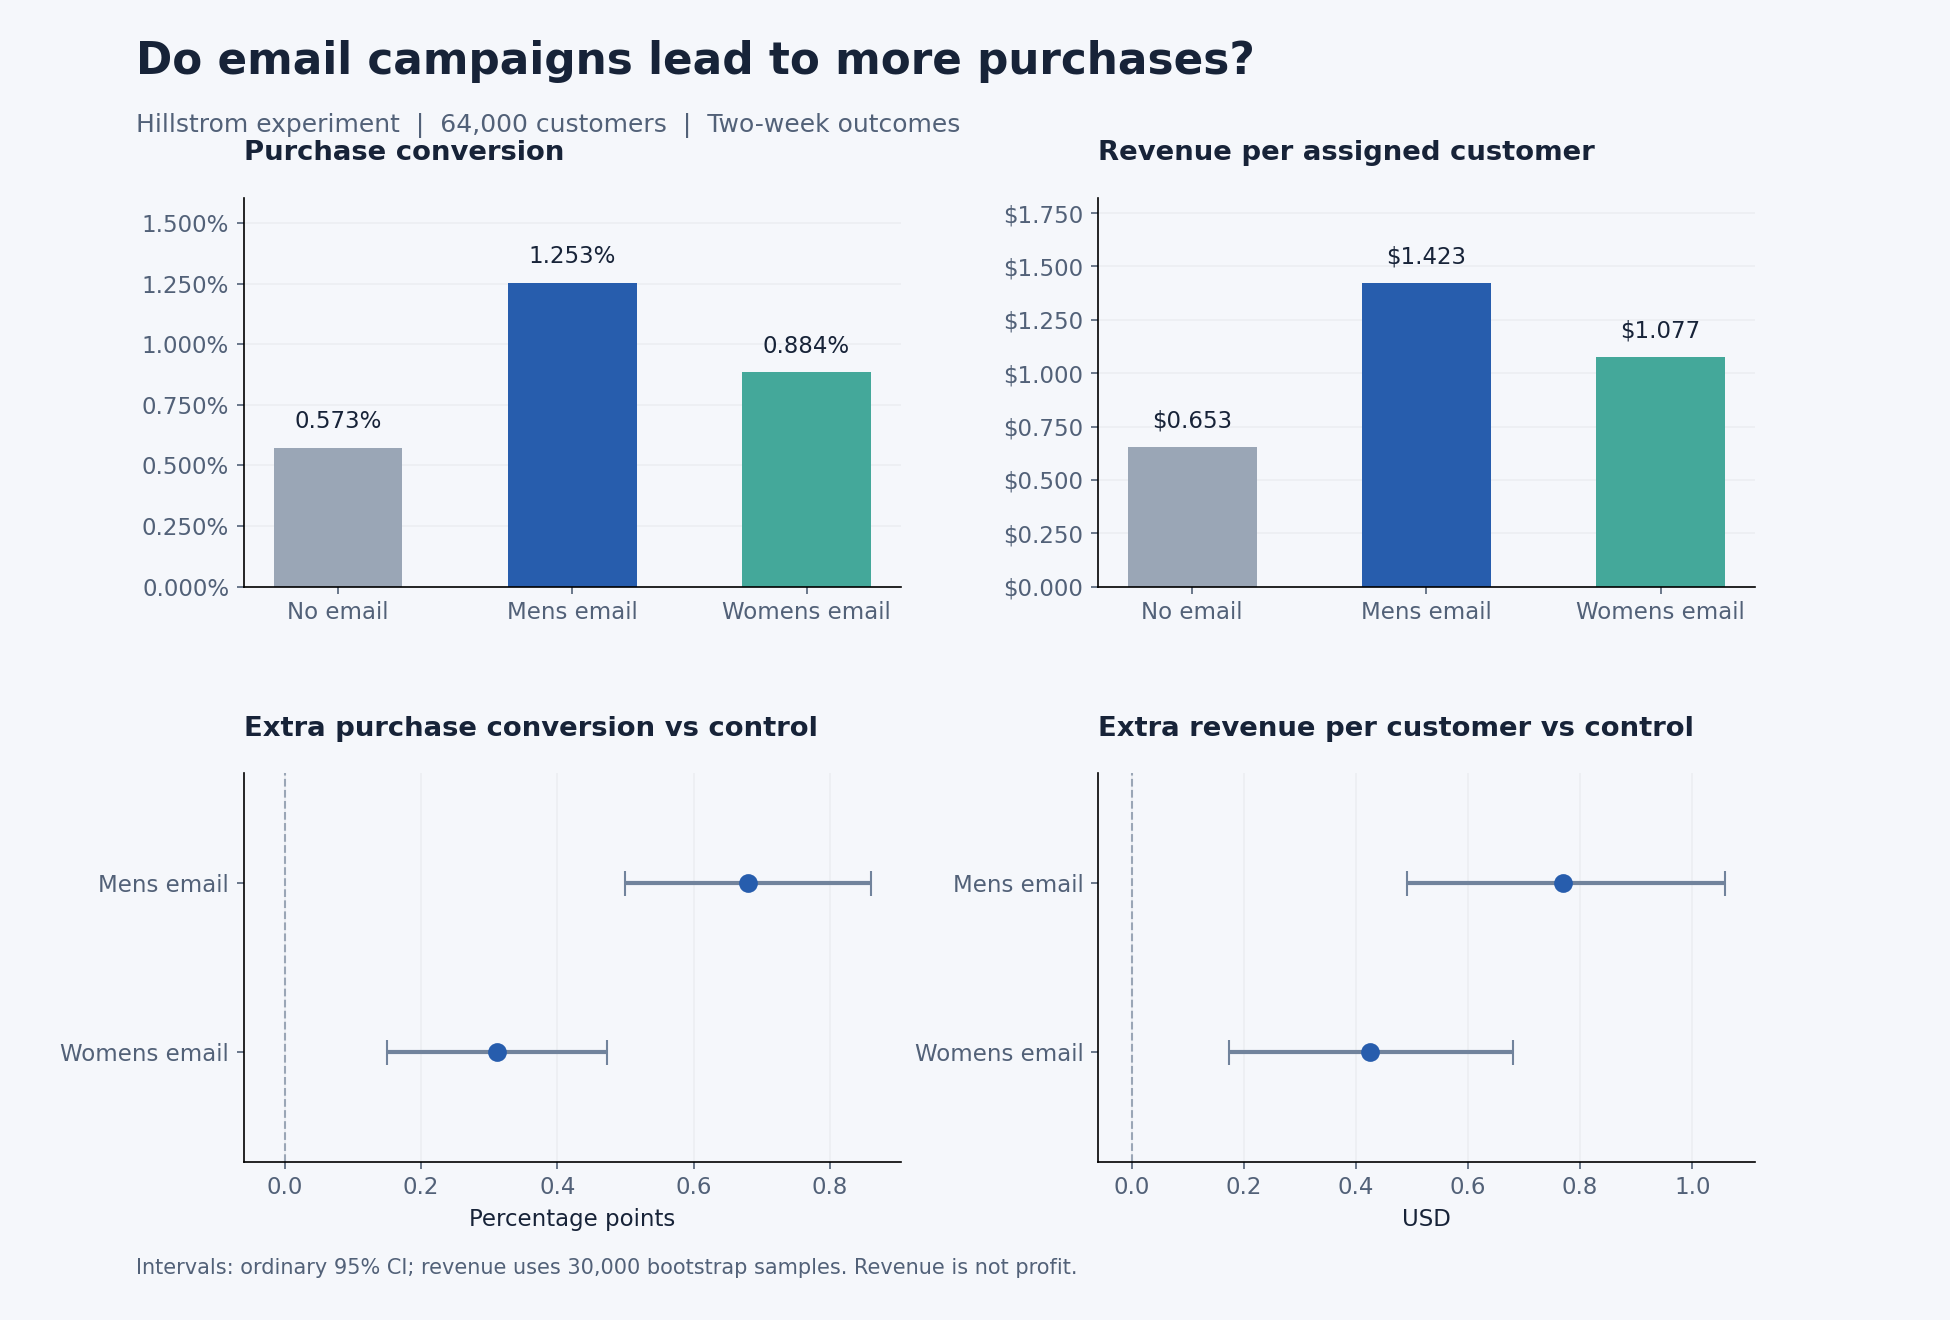

In [7]:
create_figures(summary, effects, root / 'reports/figures')
display(Image(filename=str(root / 'reports/figures/overview.png')))

## 8. Перевожу эффект в понятный масштаб

Это ожидаемый дополнительный результат на 10 000 сопоставимых клиентов за две недели. Он не является новым фактически проведённым экспериментом.

In [8]:
audience = 10000
projected = effects[effects.metric.isin(['conversion', 'spend'])].copy()
projected['increment_per_10000'] = projected.effect * audience
projected['ci95_low_per_10000'] = projected.ci95_low * audience
projected['ci95_high_per_10000'] = projected.ci95_high * audience
display(projected[['metric', 'treatment', 'increment_per_10000', 'ci95_low_per_10000', 'ci95_high_per_10000']])

,metric,treatment,increment_per_10000,ci95_low_per_10000,ci95_high_per_10000
0,conversion,Mens E-Mail,68.050065,50.001714,86.098417
1,conversion,Womens E-Mail,31.110575,14.986778,47.234372
4,spend,Mens E-Mail,7698.271559,4911.213293,10590.079638
5,spend,Womens E-Mail,4244.122159,1729.825991,6805.129092


## Вывод

Обе рассылки увеличили конверсию относительно контроля. Для Mens оценка прироста составляет около 0,681 п. п., для Womens — 0,311 п. п. Mens выглядит более перспективным общим вариантом.

Выручка на клиента тоже выросла, но прибыльность я не оцениваю: нет маржи и стоимости кампаний. Исторические данные не гарантируют такой же результат на современной аудитории. Для новой кампании нужен новый эксперимент.

Сегментные разрезы доступны в Superset и CSV. Я использую их для поиска будущих гипотез, а не для обещания точного эффекта персонального таргетинга.